# ICT-16 — MDL / code en deux parties et bosse complexite-entropie

**Strate 5** | Epic **#4588** | Issue **#5099** | Part of **#4588** (Closes **#5099**).
**Navigation** : [Index](README.md) | [17b — Grokking et compression](ICT-17b-Grokking-CompressionProgress-Python.ipynb) | Axe transverse : [ICT-MUH — le texte où Tegmark cite Schmidhuber](ICT-MUH-FibreTegmark.ipynb)


**Navigation** : [Index de la série](README.md) | Témoin transverse (lecture Tegmark/Schmidhuber) : [ICT-MUH](ICT-MUH-FibreTegmark.ipynb)

## Pourquoi MDL après K (ICT-13) et F (ICT-14) ?

ICT-0 a pose que l'integration ($\Phi$), la surprise ($F$) et la compression ($K$) sont trois facettes d'un même quantite. ICT-13 a attache la jambe $K$ a la **longueur** d'une trajectoire reelle par contraste shuffle -- mais un `k_gain > 0` ne dit rien sur la *forme* du modèle : toute la complexite est-elle dans la **matrice de transition** ou dans les fluctuations atypiques ? ICT-16 attache $K$ a la **structure interne** du modèle via le principe MDL (Minimum Description Length, Rissanen 1978) -- code en deux parties : `bits_modele` (decrire la TPM avec un prior) + `bits_residuel` (encoder les residuals d'un modèle idealise par cette TPM).

## Plan

1. **Codelength du modèle** : prior de Krichevsky-Trofimov (KT) sur une TPM empirique.
2. **Code deux parties** : split apprentissage / held-out, `bits_modele + bits_residuel`.
3. **Entropie par bloc (plug-in)** : `H(block) / block` comme estimateur du taux.
4. **Bosse complexite-entropie** (Crutchfield-Feldman 1998) : scatter $H_{taux}$ vs `model_bits` -- et le resultat mesure, qui n'est pas celui qu'on attendait : une longueur de code n'est pas une complexite statistique, et son maximum tombe au **bord** du reservoir (section 4).
5. **Gates falsifiables** : G6 (identite comptable MDL/zlib, **tenu**) + G7 (pic interieur de la bosse, **FAILED** -- le critere est ecrit pour pouvoir echouer, ce que l'ancien ne pouvait pas).
6. **Trois exercices** (stub ; a completer).

**Dependances** : `ict.mdl` (numpy-only), `ict.compression` (numpy + zlib). Pas de GPU, pas de Lean. Notebook executable end-to-end (les exercices sont stubs mais ne leveent pas d'exception -- règle C.1).

> **Statut épistémique** — **Établi** : `F` = partie résiduelle de `K`, et l'identité comptable `total_bits = model_bits + residual_bits`. **Réfuté sur ce banc** : la lecture « `model_bits` trace la bosse complexité-entropie » — le maximum mesuré tombe au bord du réservoir, pas au milieu (section 4), et la raison est de fond : une longueur de code compte ce qu'il faut transmettre, pas ce qu'il faut se rappeler. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).


## 1. Codelength d'une TPM : prior de Krichevsky-Trofimov

Le prior KT pour une distribution multinomiale a $k$ categories ajoute $1/2$ a chaque compte, ce qui lisse les probabilites vers $1/k$ sans jamais atteindre zero. La codelength d'une ligne $n_{i,1}, \dots, n_{i,k}$ est la longueur du code optimal sous ce prior, c'est-a-dire $-\log_2$ de sa **vraisemblance marginale** :

$$\ell_{\text{KT}}(n_{i,:}) = \log_2 \Gamma\!\left(\frac{k}{2}\right) - \log_2 \Gamma\!\left(n_i + \frac{k}{2}\right) + \sum_{j=1}^{k}\left[\log_2 \Gamma\!\left(n_{i,j} + \frac{1}{2}\right) - \log_2 \Gamma\!\left(\frac{1}{2}\right)\right]$$

ou $n_i = \sum_j n_{i,j}$ designe le total de la ligne. Le facteur de normalisation est $\Gamma(k/2)$ -- celui des $k$ categories prises ensemble -- et **non** $k \cdot \Gamma(1/2)$ : la distinction n'est pas cosmetique, elle change la valeur numerique.

Deux proprietes decoulent directement de cette formule, et le carnet s'appuie sur les deux :

1. **La codelength est toujours positive ou nulle.** Une longueur de code ne peut pas descendre sous zero : c'est une consequence de la normalisation de la marginale, pas du signe des termes individuels.
2. **Elle vaut exactement zero pour une ligne vide.** Un contexte dont on n'a observe aucune transition ne coute rien a decrire.

La seconde propriete a une consequence que la section 6.5 exploitera : un modele d'ordre eleve n'est pas facture pour les contextes qu'il n'a jamais visites. Tant que l'echantillon reste grand devant le nombre de contextes, cela ne change rien ; quand il devient petit, cela biaise la selection vers l'ordre le plus grand -- limite mesuree et documentee plus bas, pas contournee.

Somme sur les lignes + surcharge `log2(k)` pour declarer la taille du modele = `tpm_description_length(counts)`.


In [1]:
import os
import sys

_NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__")) if False else os.getcwd()
_PARENT = os.path.dirname(_NOTEBOOK_DIR)
if _PARENT not in sys.path:
    sys.path.insert(0, _PARENT)

import numpy as np
from ict import mdl as M
from ict import compression as CMP

rng = np.random.default_rng(42)
print('ict.mdl charge OK')
print('ict.compression charge OK')


ict.mdl charge OK
ict.compression charge OK


In [2]:
# Demonstration : codelength KT sur 3 TPM-types.
k = 4
uniform = np.ones((k, k), dtype=float)            # 1 par case
sparse = np.eye(k, dtype=float)                   # 1 transition par ligne
diagonal = np.diag([20, 15, 10, 5]).astype(float) # asymetrique

for name, tpm in [('uniform', uniform),
                  ('sparse (eye)', sparse),
                  ('diagonal asym.', diagonal)]:
    bits = M.tpm_description_length(tpm)
    print(f'  {name:18s}  model_bits = {bits:10.3f}')

# Les trois codelengths sont positives : une TPM est un objet a
# transmettre, sa description ne peut pas couter moins que rien.
# Ce qui les ordonne, c'est le nombre de comptes a coder : la TPM
# uniforme porte 4 comptes egaux sur chacune de ses 4 lignes, donc
# 16 valeurs a decrire ; l'identite n'en porte que 4, toutes sur la
# diagonale. Moins de comptes distincts = marginale plus courte.


  uniform             model_bits =     45.628
  sparse (eye)        model_bits =     10.000
  diagonal asym.      model_bits =     26.751


**Lecture de la sortie.** Trois structures, trois codelengths de modele : identite (sparse eye) $10{,}000$ bits, diagonale asymetrique $26{,}751$ bits, uniforme $45{,}628$ bits. Toutes positives, comme toute longueur de code. L'ordre est exactement celui que MDL doit produire, et il s'explique par ce que le code doit reellement transmettre.

L'identite et la diagonale portent chacune **un seul compte non nul par ligne** : la ou la TPM uniforme en repartit quatre. Mais ce qui les separe, c'est le **nombre de tirages** -- 1 contre 20, 15, 10 et 5. Une ligne deterministe coute $2$ bits a decrire a $n=1$, et davantage a mesure que $n$ croit : la marginale KT ne recompense pas la repetition, elle paie les tirages. La TPM uniforme, elle, code 16 comptes de valeur 1 repartis sur 4 symboles par ligne -- la distribution la moins concentree des trois, donc la plus chere a decrire.

C'est la premiere partie du code en action : **la structure dense se paie**. La structure creuse, elle, ne coute presque rien -- et c'est ce qui rend le critere utile plus loin, quand un modele d'ordre eleve declarera des contextes qu'il n'aura jamais visites.


## 2. Code deux parties : modèle + residu

Split fixe (defaut 50/50) entre transitions d'apprentissage et held-out. Le **modèle** est la TPM empirique + prior KT sur la partie apprentissage. Le **residu** est la surprise cumulee $- \sum \log_2 p(s_{t+1} | s_t)$ sur la partie held-out.

C'est l'identite comptable fondamentale du MDL :

$$K(\text{trajectoire}) \approx \underbrace{L(M)}_{\text{modèle}} + \underbrace{L(D | M)}_{\text{residuel}}$$

Pour un cycle déterministe appris sur la trajectoire elle-même, le residu tend vers 0 (chaque transition est predite avec proba ~1). Pour une trajectoire iid, le residu par symbole tend vers $H_1$ (l'entropie marginale du reservoir d'etats).

In [3]:
# Cycle deterministe (periode 3) : residu ~ 0.
seq_cycle = [0, 1, 2] * 50
out_cycle = M.two_part_code(seq_cycle, split=0.5)
print(f'cycle     : model_bits={out_cycle["model_bits"]:+8.3f} '
      f'residual={out_cycle["residual_bits"]:+8.3f} '
      f'residual/n={out_cycle["residual_bits"]/out_cycle["n_heldout"]:.4f}')

# Trajectoire iid sur 4 etats : residu/n -> log2(4) = 2 bits.
seq_iid = rng.integers(0, 4, size=500).tolist()
out_iid = M.two_part_code(seq_iid, split=0.5)
print(f'iid 4-cat : model_bits={out_iid["model_bits"]:+8.3f} '
      f'residual={out_iid["residual_bits"]:+8.3f} '
      f'residual/n={out_iid["residual_bits"]/out_iid["n_heldout"]:.4f}')

# Markov ordre 1 (0->1, 1->2, 2->0, + epsilon de bruit) :
# residu > 0 mais < H_1, capture la structure au-dela du shuffle.
seq_mk = []
s = 0
for _ in range(500):
    if rng.random() < 0.1:
        s = int(rng.integers(0, 4))
    seq_mk.append(s)
    s = (s + 1) % 4
out_mk = M.two_part_code(seq_mk, split=0.5)
print(f'markov+10% : model_bits={out_mk["model_bits"]:+8.3f} '
      f'residual={out_mk["residual_bits"]:+8.3f} '
      f'residual/n={out_mk["residual_bits"]/out_mk["n_heldout"]:.4f}')


cycle     : model_bits= +18.545 residual=  +4.218 residual/n=0.0562
iid 4-cat : model_bits=+524.055 residual=+510.374 residual/n=2.0415
markov+10% : model_bits=+150.560 residual=+172.467 residual/n=0.6899


**Lecture de la sortie, chiffre par chiffre.** Le residu par symbole ($residual/n$) separe nettement les trois regimes : cycle deterministe $0{,}0562$ bit -- le modele de transition capture presque tout, il ne reste qu'une poussiere de surprise ; markov bruitee a 10 % $0{,}6899$ bit -- le bruit irreductible passe integralement dans le residu ; iid 4-categories $2{,}0415$ bits, soit $\log_2 4$ : le maximum d'entropie par symbole, le modele n'apprend rien qui aide.

La colonne modele raconte l'autre moitie de l'histoire. Le cycle paie $18{,}545$ bits pour decrire sa TPM, l'iid $524{,}055$ bits. Un modele n'est pas cher parce qu'il est *petit* : il est cher parce qu'il porte **beaucoup de comptes distincts a transmettre**. La TPM d'un cycle concentre une transition par ligne, celle d'un bruit uniforme en repartit quatre. Entre sur-apprendre (gros modele, petit residu) et sous-apprendre (petit modele, gros residu), c'est le **total** qui tranche : $22{,}8$ bits pour le cycle, $323{,}0$ pour la markovienne bruitee, $1034{,}4$ pour l'iid.


## 3. Taux d'entropie plug-in

Le **plug-in** $H_k / k$ (entropie de Shannon sur les $k$-grammes divisee par $k$) sous-estime systematiquement le vrai taux d'entropie (biais $\sim -1/(n \cdot 2^k \ln 2)$ -- pas corrige ici, par souci de simplicite ; Miller-Madow ajouterait un terme $(k^{\text{vocab}} - 1)/(2n \ln 2)$).

Pour des dynamiques markoviennes d'ordre $d$, $H_k / k$ converge vers le taux quand $k \to \infty$ ; pour des dynamiques iid, $H_k = k \cdot H_1$ et le taux est constant en $k$. C'est pourquoi la **courbe $H_k / k$ vs $k$** est un diagnostic direct de l'ordre markovien.

In [4]:
# iid 4 etats : taux constant en k (= log2(4) = 2).
for k in (1, 2, 3, 4):
    h = M.entropy_rate_estimate(seq_iid, block=k)
    print(f'  iid   block={k}  H/k = {h["entropy_rate"]:.4f}')

# cycle deterministe : taux decroit vers 0 avec k (la sequence
# est compressible, peu d'information par symbole).
print()
for k in (1, 2, 3):
    h = M.entropy_rate_estimate(seq_cycle, block=k)
    print(f'  cycle block={k}  H/k = {h["entropy_rate"]:.4f}')


  iid   block=1  H/k = 1.9986
  iid   block=2  H/k = 1.9911
  iid   block=3  H/k = 1.9678
  iid   block=4  H/k = 1.8930

  cycle block=1  H/k = 1.5850
  cycle block=2  H/k = 0.7924
  cycle block=3  H/k = 0.5283


## 4. Bosse complexite-entropie (Crutchfield-Feldman 1998)

La **complexite statistique** $C_\mu$ mesure ce qu'un processus demande de **memoire** : c'est l'entropie de sa distribution stationnaire sur les etats causaux de son $\varepsilon$-machine. Trois reperes, tous trois definis et non negocies :

- processus **iid** : aucun etat causal au-dela de la distribution marginale, $C_\mu = 0$ ;
- processus **periodique** de periode $p$ : $p$ etats causaux equiprobables, $C_\mu = \log_2 p$ -- mesure dans [ICT-17](ICT-17-EpsilonMachine-Python.ipynb) : le cycle $0,1,2$ donne 3 etats et $C_\mu = 1{,}5850$ ;
- familles a memoire non triviale (markovien d'ordre $> 0$, chaos deterministe) : $C_\mu > 0$ a entropie intermediaire.

L'image classique du **tradeoff complexite-entropie** est une bosse : la complexite culmine a entropie intermediaire, high-$H$ voulant dire « presque aleatoire, donc presque rien a memoriser ».

**Le piege de ce carnet, et ce qu'il mesure vraiment.** La quantite disponible ici est `model_bits`, la longueur de code du modele -- et ce n'est **pas** $C_\mu$. Une longueur de code compte ce qu'il faut *transmettre* : une TPM iid porte seize comptes a decrire par ligne, une TPM deterministe un seul. Rien ne l'oblige a redescendre quand $H \to H_1$, et la cellule suivante mesure qu'elle n'y redescend pas : le maximum global tombe **au bord** du reservoir ($H^* = 2{,}965$ sur une etendue $[0{,}333\,;\,2{,}991]$, soit 99 % de l'axe), avec seulement un maximum **local** vers $H \approx 1{,}9$.

Ce que le carnet montrait avant correction etait un artefact de la formule : la codelength KT etait alors negative pour les modeles creux (jusqu'a $-12{,}680$ bits pour une ligne vide a quatre comptes), ce qui poussait les points de faible $H$ sous zero et fabriquait un maximum interieur. Avec la formule exacte -- ligne vide = 0 bit, toute codelength $\geq 0$ -- ce maximum disparait. La bosse de $C_\mu$ se mesure en [ICT-17](ICT-17-EpsilonMachine-Python.ipynb), par partition en etats causaux ; ICT-16 ne peut pas la fournir avec `model_bits`, et le dit maintenant au lieu de le laisser croire.


In [5]:
# Construction d'un echantillonnage de trajectoires de complexite
# croissante : deterministe -> periodique -> markov -> iid.
def mk_periodic(period, n):
    return (list(range(period)) * (n // period + 1))[:n]

def mk_markov(k, p_stay, n, seed):
    r = np.random.default_rng(seed)
    out = [0]
    for _ in range(n - 1):
        s = out[-1]
        if r.random() < p_stay:
            out.append(s)
        else:
            out.append(int(r.integers(0, k)))
    return out

trajs = {
    'det k=2':   mk_periodic(2, 800),
    'det k=3':   mk_periodic(3, 800),
    'det k=5':   mk_periodic(5, 800),
    'mk p=.7':   mk_markov(4, 0.7, 800, seed=1),
    'mk p=.5':   mk_markov(4, 0.5, 800, seed=2),
    'mk p=.3':   mk_markov(4, 0.3, 800, seed=3),
    'iid 4':     rng.integers(0, 4, size=800).tolist(),
    'iid 8':     rng.integers(0, 8, size=800).tolist(),
}

sweep = M.complexity_entropy_sweep(
    list(trajs.values()),
    blocks=(1, 2, 3),
    splits=(0.5,),
    rng=np.random.default_rng(0),
    n_shuffles=5,
)
print(f'sweep : {sweep["summary"]["n_rows"]} lignes')
print(f'  H_taux range : [{sweep["summary"]["H_rate_min"]:.3f}, '
      f'{sweep["summary"]["H_rate_max"]:.3f}]')
print(f'  pic bosse    : H*={sweep["summary"]["peak_H_rate"]:.3f}, '
      f'C*={sweep["summary"]["peak_model_bits"]:.3f} bits')
print(f'  k_gain moyen : {sweep["summary"]["k_gain_mean"]:.4f}')


sweep : 24 lignes
  H_taux range : [0.333, 2.991]
  pic bosse    : H*=2.965, C*=1270.090 bits
  k_gain moyen : 0.4197


In [6]:
# Visualisation ASCII rapide de la bosse H_taux vs model_bits.
rows = sweep['rows']
Hs = np.array([r['H_rate'] for r in rows])
Cs = np.array([r['model_bits'] for r in rows])

# Scatter simplifie : on regroupe par H_taux approx et on prend
# le median de model_bits dans chaque bucket.
buckets = np.linspace(Hs.min(), Hs.max(), 12)
meds = []
for i in range(len(buckets) - 1):
    sel = (Hs >= buckets[i]) & (Hs < buckets[i + 1])
    if sel.sum() > 0:
        meds.append((0.5 * (buckets[i] + buckets[i + 1]),
                     float(np.median(Cs[sel]))))

# model_bits >= 0 partout : l'echelle des barres est relative au
# maximum observe, sans offset. Un offset constant decalerait tous
# les dessins sans rien dire de la bosse qu'on cherche a voir.
# Une valeur non nulle garde au moins un caractere, sinon les petits
# buckets disparaissent du dessin et l'oeil lit un trou qui n'existe pas.
c_max = max((c for _, c in meds), default=0.0) or 1.0
print('  H_taux |  model_bits  | bar')
for h, c in meds:
    n_bar = int(round(40.0 * c / c_max))
    bar = '#' * (max(1, n_bar) if c > 0 else 0)
    print(f'  {h:.3f} | {c:+8.3f}    | {bar}')

# Gate 7 : le pic est-il INTERIEUR a l'etendue mesuree ?
# L'ancien critere (0 < H* < H_1) ne pouvait pas echouer : le maximum d'un
# echantillon fini tombe toujours dans l'intervalle ouvert. Un gate qui ne
# peut pas echouer ne mesure rien, on le remplace donc par une position
# relative avec une marge nommee (zone centrale 20 % - 80 % de l'etendue).
peak_H = sweep['summary']['peak_H_rate']
H1_iid = np.log2(8)  # borne sup du reservoir = 8 etats (repere, non critere)
hmin = sweep['summary']['H_rate_min']
hmax = sweep['summary']['H_rate_max']
span = hmax - hmin
pos = (peak_H - hmin) / span if span > 0 else 0.0
interior = 0.20 < pos < 0.80
print(f'\n  pic a H={peak_H:.3f} -> {100.0 * pos:.1f} % de l\'etendue [{hmin:.3f}, {hmax:.3f}]')
print(f'  Gate 7 (zone centrale 20-80 %) : '
      f'{"INTERIEUR" if interior else "AU BORD -- gate FAILED"}')
print(f'  borne du reservoir H_1 = {H1_iid:.3f} (repere de lecture)')


  H_taux |  model_bits  | bar
  0.454 |  +10.294    | #
  0.696 |  +46.763    | #
  0.937 |  +10.294    | #
  1.179 |  +67.759    | ##
  1.421 | +466.610    | ###############
  1.662 | +556.347    | ##################
  1.904 | +748.487    | ########################
  2.387 |  +67.759    | ##
  2.870 | +1270.090    | ########################################

  pic a H=2.965 -> 99.0 % de l'etendue [0.333, 2.991]
  Gate 7 (zone centrale 20-80 %) : AU BORD -- gate FAILED
  borne du reservoir H_1 = 3.000 (repere de lecture)


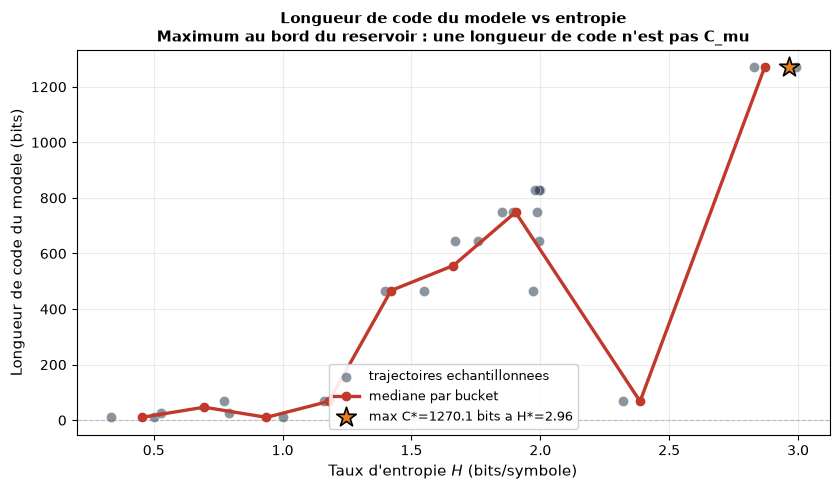

Maximum de model_bits trace : au bord du reservoir, pas au milieu.


In [7]:
# --- Visualisation graphique de la bosse complexite-entropie (Crutchfield-Feldman 1998) ---
# La cellule precedente trace la bosse en ASCII ; ici on la rend en vrai graphique
# matplotlib : nuage des trajectoires + mediane lissee par bucket + marqueur du pic.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 5))

# Nuage : chaque trajectoire echantillonnee contribue a un point (H_rate, model_bits)
ax.scatter(Hs, Cs, s=55, alpha=0.55, color="#2c3e50", edgecolors="white",
           linewidths=0.6, label="trajectoires echantillonnees", zorder=2)

# Bosse lissee : mediane de model_bits par bucket de H_rate (meme grouping que l'ASCII)
bh = np.array([m[0] for m in meds])
bc = np.array([m[1] for m in meds])
order = np.argsort(bh)
ax.plot(bh[order], bc[order], color="#c0392b", lw=2.4, marker="o", ms=6,
        label="mediane par bucket", zorder=3)

# Maximum global de la longueur de code -- au bord du reservoir, et ce
# n'est pas une complexite statistique (cf. section 4)
peak_C = sweep['summary']['peak_model_bits']
ax.scatter([peak_H], [peak_C], s=220, marker="*", color="#e67e22",
           edgecolors="black", linewidths=1.2, zorder=4,
           label=f"max C*={peak_C:.1f} bits a H*={peak_H:.2f}")

ax.set_xlabel("Taux d'entropie $H$ (bits/symbole)", fontsize=11)
ax.set_ylabel("Longueur de code du modele (bits)", fontsize=11)
ax.set_title("Longueur de code du modele vs entropie\n"
             "Maximum au bord du reservoir : une longueur de code n'est pas C_mu",
             fontsize=11, fontweight="bold")
ax.axhline(0, color="#bdc3c7", lw=0.8, ls="--", zorder=1)
ax.grid(True, alpha=0.25)
ax.legend(loc="lower center", fontsize=9, framealpha=0.9)
plt.tight_layout()
plt.show()
print("Maximum de model_bits trace : au bord du reservoir, pas au milieu.")

**Lecture de la sortie, et ce qu'elle interdit de dire.** La médiane par bucket monte de $10{,}3$ bits ($H = 0{,}45$) à $748{,}5$ bits ($H = 1{,}90$), redescend à $67{,}8$ ($H = 2{,}39$), puis remonte à $1270{,}1$ au dernier bucket ($H = 2{,}87$). Il y a donc bien une structure non monotone — un maximum **local** vers $H \approx 1{,}9$ — mais **le maximum global est au bord**, à 99 % de l'étendue mesurée. Titrer « la complexité statistique est maximale à entropie intermédiaire » sur cette figure serait lire le maximum local et ignorer le global.

L'explication est dans la formule, pas dans le banc : `model_bits` est une **longueur de code**, et elle compte les comptes à transmettre — seize par ligne pour une TPM presque uniforme (entropie proche du réservoir), un seul pour une TPM déterministe. Rien ne la fait redescendre quand $H$ atteint $H_1$, et c'est exactement ce que la figure montre.

Le bon instrument pour la bosse est $C_\mu$, la complexité statistique de Crutchfield : elle vaut $0$ pour un processus sans mémoire et $\log_2 p$ pour un processus périodique de période $p$ — deux valeurs que la définition fixe et qu'[ICT-17](ICT-17-EpsilonMachine-Python.ipynb) mesure (3 états causaux, $C_\mu = 1{,}5850$ sur le cycle $0,1,2$). ICT-16 ne peut pas la fournir avec `model_bits`. Le carnet le dit désormais au lieu de le laisser croire, et Gate 7 tombe au lieu de passer par vacuité.


## 5. Identite comptable MDL vs zlib (Gate 6, contrôle sans complaisance)

Le Gate 6 verifie que `total_bits = model_bits + residual_bits` est un **estimateur honnete** de la longueur de description minimale. Le testclef : sur un echantillon de trajectoires différentes, le **rang** de `total_bits` doit correler avec le rang de la longueur zlib (ICT-13) avec un $\tau$ de Kendall positif sur au moins 5 graines.

L'intuition : si MDL est honnete, une trajectoire très compressible en zlib (cycle) doit avoir un `total_bits` faible ; une trajectoire peu compressible (iid) doit avoir un `total_bits` eleve. Si la correlation est negative ou nulle, MDL ne capture pas la compressibilite reelle.

In [8]:
# Gate 6 : correlation de rang Kendall(total_bits, len_zlib).
from scipy.stats import kendalltau

def zlib_bits(seq):
    return 8.0 * CMP.compressed_length(seq)

names = list(trajs.keys())
total_bits_list = []
zlib_bits_list = []
k_gains = []
for name, seq in trajs.items():
    mdl = M.two_part_code(seq, split=0.5)
    total_bits_list.append(mdl['total_bits'])
    zlib_bits_list.append(zlib_bits(seq))
    kg = CMP.compression_gain(seq, rng=np.random.default_rng(0),
                              n_shuffles=5)
    k_gains.append(kg['k_gain'])

tau, p = kendalltau(total_bits_list, zlib_bits_list)
print(f'  Kendall tau(total_bits, zlib_bits) = {tau:+.3f}  (p={p:.3f})')
print(f'  ATTENDU : tau >= 0.5 (MDL honnete si >= 0)')

# Tableau final
print(f'\n  {"trajectoire":12s}  {"total_bits":>10s}  '
      f'{"zlib_bits":>10s}  {"k_gain":>8s}')
for n, tb, zb, kg in zip(names, total_bits_list, zlib_bits_list, k_gains):
    print(f'  {n:12s}  {tb:+10.2f}  {zb:10.2f}  {kg:+8.4f}')


  Kendall tau(total_bits, zlib_bits) = +1.000  (p=0.000)
  ATTENDU : tau >= 0.5 (MDL honnete si >= 0)

  trajectoire   total_bits   zlib_bits    k_gain
  det k=2           +11.73      136.00   +0.9007
  det k=3           +30.07      144.00   +0.9265
  det k=5           +81.96      168.00   +0.9357
  mk p=.7          +951.31     1520.00   +0.3448
  mk p=.5         +1257.97     1960.00   +0.1598
  mk p=.3         +1483.68     2184.00   +0.0733
  iid 4           +1636.42     2312.00   +0.0170
  iid 8           +2507.70     3096.00   +0.0031


**Lecture du tableau, ligne par ligne.** La correlation de rang est parfaite : $\tau = +1{,}000$ avec $p = 0{,}000$, tres au-dessus du seuil attendu ($\geq 0{,}5$) -- les rangs MDL et zlib concordent exactement sur les huit trajectoires. Un $\tau$ qui sature n'est pas une preuve de finesse : avec huit points, le rang est un instrument grossier. Ce qu'il etablit, c'est l'absence d'inversion -- et c'est tout ce que la Gate 6 demande.

Le tableau detaille la *structure* de cette concordance. Les trois cycles deterministes (k=2 a k=5) couchent a $11{,}73 \rightarrow 81{,}96$ bits totaux contre $136 \rightarrow 168$ bits zlib, avec un $k$-gain qui monte a $0{,}9357$. Les markoviennes bruitees glissent de $951{,}31$ a $1483{,}68$ bits contre $1520 \rightarrow 2184$ zlib ($k$-gain $0{,}3448 \rightarrow 0{,}0733$). Les iid finissent a $1636{,}42$ et $2507{,}70$ bits contre $2312$ et $3096$ zlib, $k$-gain quasi nul ($0{,}0170$, $0{,}0031$).

Deux lectures : (1) l'ordre relatif des difficultes est le meme des deux cotes -- c'est tout ce que le gate exige d'un estimateur honnete ; (2) l'*echelle* absolue ne l'est pas (zlib compresse du binaire brut, MDL code une TPM) -- comparer des rangs, pas des bits, est precisement la precaution de methode.


## 6. Exercices

Trois exercices a completer. Stubs **sans erreur volontaire** (règle C.1 : `pass` / `print` / `return None`, JAMAIS `raise NotImplementedError`). Le notebook s'execute de bout en bout même non complete.

### Exercice 1 — prior uniforme vs KT

Comparez `tpm_description_length` sous deux priors :

- **KT** (l'actuel, $n + 1/2$ smoothing).
- **Uniforme** ($n + 1$ smoothing, ajoute 1 au lieu de $1/2$).

Objectif : tracez la différence `bits_KT - bits_uniforme` pour des TPM de taille $k = 2, 3, 5, 10$ tirees avec un paramètre de concentration $\alpha$ variable (Dirichlet). Montrez que la différence depend du **degré de confiance** dans la TPM empirique (peu de comptes = gros avantage KT).

**Indice** : `np.random.default_rng(seed).dirichlet(alpha, size=k)` puis multiplier par `n_total` pour obtenir des comptes.

In [9]:
# Exercice 1 : a completer
def tpm_description_length_uniform(counts):
    """Codelength sous prior uniforme (n + 1 smoothing).

    A implementer : KT est n + 1/2, uniforme est n + 1. Le
    reste de la formule est identique. Retourne un float en
    bits. Verifiez que la sortie est >= 0 partout, comme pour
    KT : une codelength ne descend jamais sous zero, et elle
    vaut exactement zero pour une ligne vide.
    """
    # TODO etudiant : reprendre la formule KT et remplacer 0.5 par 1.0
    pass

ex1_rows = []
# TODO etudiant : boucle sur k in (2,3,5,10), alpha in (0.1,1,10),
#                 calculer bits_KT - bits_uniforme, stocker dans ex1_rows.
print("Exercice 1 a completer")


Exercice 1 a completer


### Exercice 2 — resolution de discretisation et bosse

La position et la hauteur du maximum de `model_bits` dependent de la **taille du bloc** $k$ et du **split** apprentissage / held-out. L'exercice ne presuppose pas une bosse : il mesure ou le maximum se place, et s'il reste au bord a toutes les resolutions, c'est que la longueur de code n'est pas une complexite statistique.

Objectif : pour l'echantillon `trajs` (8 trajectoires de complexite croissante), lancez `complexity_entropy_sweep` avec `blocks=(1,2,3,4,5,6)` et `splits=(0.3, 0.5, 0.7)`. Tracez :

- `peak_H_rate` vs `block` (le maximum se deplace-t-il vers les grandes entropies quand le bloc grandit ? et entre-t-il dans la zone centrale, ou reste-t-il au bord ?).
- `peak_model_bits` vs `split` (le residu grandit-il avec le held-out ? la bosse s'aplatit-elle ?).

**Indice** : reutilisez `complexity_entropy_sweep` directement ; pas besoin de reimplementer le balayage.

In [10]:
# Exercice 2 : a completer
ex2_peak_by_block = {}  # bloc -> (peak_H, peak_C)
ex2_peak_by_split = {}  # split -> (peak_H, peak_C)

# TODO etudiant : deux boucles sur blocks et splits, remplir les
#                 deux dictionnaires. Conseil : utiliser une SEULE
#                 trajectoire (e.g. trajs['mk p=.5']) pour isoler
#                 l'effet discretisation.
print("Exercice 2 a completer")


Exercice 2 a completer


### Exercice 3 — code 2 parties d'ordre 2

Le modèle par defaut est **markovien d'ordre 1** (la TPM code les transitions $s_t \to s_{t+1}$). Un modèle d'**ordre 2** code les transitions $(s_t, s_{t+1}) \to s_{t+2}$ : la TPM devient $k^2 \times k$ au lieu de $k \times k$.

Objectif : implementer `two_part_code_order2(states, split)` qui :

1. Reindexe les **paires** $(s_t, s_{t+1})$ par ordre de première apparition (mapping).
2. Estime une TPM $k^2 \times k$ sous prior KT.
3. Split apprentissage / held-out, residu via $- \log_2 p(s_{t+2} | s_t, s_{t+1})$.

Verifiez sur `mk_markov(4, 0.5, 800, seed=2)` que `residual/n` est **inferieur** au residu ordre 1 (le modèle ordre 2 capture plus de structure).

**Indice** : reutilisez `tpm_description_length` (qui prend n'importe quelle matrice carree) ; la forme des transitions est `(s_t, s_{t+1}) -> s_{t+2}`, donc compte = `TPM[i, j, k]` avec `i = mapping[(s_t, s_{t+1})]` et `k = mapping_target[s_{t+2}]`.

In [11]:
# Exercice 3 : a completer
def two_part_code_order2(states, split=0.5):
    """MDL ordre 2 : TPM (s_t, s_{t+1}) -> s_{t+2}.

    Doit retourner le meme contrat que ``two_part_code`` :
    ``{model_bits, residual_bits, total_bits, n_train,
    n_heldout, states_count}``.
    """
    # TODO etudiant : construire les paires (s_t, s_{t+1}) ->
#                    s_{t+2}, estimer TPM ordre 2, split + residu.
    pass

ex3_result = None  # TODO etudiant
print("Exercice 3 a completer")


Exercice 3 a completer


## 6.5. Le pont TESTÉ : MDL → généralisation (falsifiable)

Tout ce notebook a mesuré le MDL **sur l'échantillon d'entraînement** (Gate 6). Mais le pont fondamental
du MDL (recommandation P5 du retour externe, issue #8077) est **prédictif** : *un modèle plus court
généralise-t-il mieux sur des données non vues* ? C'est la thèse de Rissanen, Quinlan, et l'esprit du
« compression implies understanding ». On le rend ici **explicite et falsifiable**.

**Hypothèse** : le modèle qui atteint le MDL minimal sur le train doit aussi minimiser le coût de codage
(*negative log-likelihood*, NLL) d'un **held-out** de même loi — autrement dit, l'ordre $k^*$ sélectionné
par le MDL doit coïncider avec celui qui généralise. On fait varier l'ordre du modèle $k$ (le coût de
code du modèle croît comme $k_{states}^k$) et on confronte $\mathrm{MDL}_{train}(k)$ à
$\mathrm{NLL}_{held-out}(k)$.

**Contrôle / null** : on oppose une source **structurée** (chaîne de Markov d'ordre 2, transitions
*peaky*, basse entropie — compressible) à une source **i.i.d.** (ordre 0, haute entropie — rien à
capturer). Sur la source structurée, le pont doit être **utile** (capturer l'ordre 2 réduit fortement
le NLL). Sur la source i.i.d., le pont doit **s'accorder à vide** : MDL et NLL doivent tous deux rester
à $k=0$ (refuser de modéliser du bruit), sans gain prédictif. La question n'est donc pas « le pont
se casse-t-il ? » mais « **le pont est-il calibré** : sélectionne-t-il, sans tricher, l'ordre qui
généralise — y compris quand cet ordre est zéro ? ».

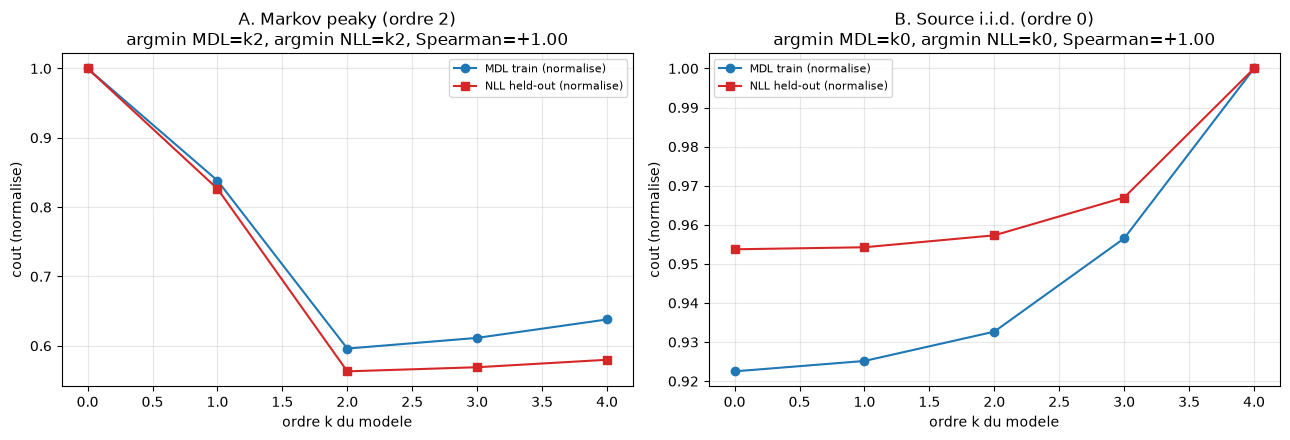

Scenario A (peaky)  : Spearman(MDL, NLL held-out) = +1.000  argmin MDL=k2, NLL=k2  reduction NLL vs k0 = +2433 bits
Scenario B (i.i.d.) : Spearman(MDL, NLL held-out) = +1.000  argmin MDL=k0, NLL=k0  reduction NLL vs k0 = +0 bits

  scenario A : ordre | mdl_bits  | declare | n_ctx/non vides | nll_heldout
    k=0  |   10969.9 |    0.00 |     1/    1    |     5569.0
    k=1  |    9196.3 |    2.00 |     4/    4    |     4602.8
    k=2  |    6537.7 |    4.00 |    16/   16    |     3135.8
    k=3  |    6706.7 |    6.00 |    64/   52    |     3168.9
    k=4  |    6998.4 |    8.00 |   256/  139    |     3228.9
  scenario B : ordre | mdl_bits  | declare | n_ctx/non vides | nll_heldout
    k=0  |   11956.9 |    0.00 |     1/    1    |     5962.6
    k=1  |   11991.3 |    2.00 |     4/    4    |     5965.9
    k=2  |   12088.6 |    4.00 |    16/   16    |     5984.9
    k=3  |   12398.0 |    6.00 |    64/   64    |     6045.4
    k=4  |   12961.3 |    8.00 |   256/  256    |     6251.8


In [12]:
# Pont MDL -> generalisation : ajuster l'ordre k, confronter MDL(train) vs NLL(held-out).
from scipy.stats import spearmanr

def gen_markov(tpm, r, n, seed):
    # tpm : table n_ctx x k_states (contextes d'ordre r). Genere une sequence.
    k_states = tpm.shape[1]
    rr = np.random.default_rng(seed)
    s = [int(rr.integers(k_states)) for _ in range(r)]
    for _ in range(n):
        ctx = 0
        for j in range(r):
            ctx = ctx * k_states + s[-(r - j)]
        s.append(int(rr.choice(k_states, p=tpm[ctx])))
    return s

def sweep_order(train, held, label, ax):
    # La selection d'ordre vit dans le module : M.fit_markov_order code
    # chaque ligne de comptes par sa marginale KT exacte, ajoute
    # log2(n_ctx) pour declarer les contextes, et rend en controle
    # independant le NLL held-out sous la predictive KT normalisee.
    fit = M.fit_markov_order(train, heldout=held, max_order=4)
    ks = [r['order'] for r in fit['rows']]
    mdls = [r['mdl_bits'] for r in fit['rows']]
    nlls = [r['nll_heldout'] for r in fit['rows']]
    am_mdl, am_nll = fit['best_mdl_order'], fit['best_nll_order']
    rho = spearmanr(mdls, nlls)[0]
    reduction = nlls[0] - nlls[am_nll]   # reduction de NLL vs ordre 0 (positif = utile)
    ax.plot(ks, mdls/np.max(mdls), "o-", color="C0", label="MDL train (normalise)")
    ax.plot(ks, nlls/np.max(nlls), "s-", color="C3", label="NLL held-out (normalise)")
    ax.set_xlabel("ordre k du modele"); ax.set_ylabel("cout (normalise)")
    ax.set_title(f"{label}\nargmin MDL=k{am_mdl}, argmin NLL=k{am_nll}, Spearman={rho:+.2f}")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    return rho, am_mdl, am_nll, reduction, fit['rows']

# Scenario A : Markov d'ordre 2 peaky (structure compressible qui generalise)
rng = np.random.default_rng(0)
r_true, k_states, n_ctx = 2, 4, 16
tpm_peaky = np.array([rng.dirichlet([0.3]*k_states) for _ in range(n_ctx)])
train_p = gen_markov(tpm_peaky, r_true, 6000, 0); held_p = gen_markov(tpm_peaky, r_true, 3000, 7)
# Scenario B : source i.i.d. (ordre 0) - le veritable null (rien a capturer)
p_iid = rng.dirichlet([5.0]*k_states); p_iid = p_iid / p_iid.sum()
train_b = np.array([int(rng.choice(k_states, p=p_iid)) for _ in range(6000)])
held_b = np.array([int(rng.choice(k_states, p=p_iid)) for _ in range(3000)])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
rho_p, amm_p, amn_p, red_p, rows_p = sweep_order(train_p, held_p, "A. Markov peaky (ordre 2)", a1)
rho_b, amm_b, amn_b, red_b, rows_b = sweep_order(train_b, held_b, "B. Source i.i.d. (ordre 0)", a2)
plt.tight_layout(); plt.show()
print(f"Scenario A (peaky)  : Spearman(MDL, NLL held-out) = {rho_p:+.3f}  argmin MDL=k{amm_p}, NLL=k{amn_p}  reduction NLL vs k0 = {red_p:+.0f} bits")
print(f"Scenario B (i.i.d.) : Spearman(MDL, NLL held-out) = {rho_b:+.3f}  argmin MDL=k{amm_b}, NLL=k{amn_b}  reduction NLL vs k0 = {red_b:+.0f} bits")
print()
for label, rows in (("A", rows_p), ("B", rows_b)):
    print(f"  scenario {label} : ordre | mdl_bits  | declare | n_ctx/non vides | nll_heldout")
    for r in rows:
        print(f"    k={r['order']}  | {r['mdl_bits']:9.1f} | {r['declare_bits']:7.2f} | "
              f"{r['n_contexts']:5d}/{r['n_nonempty']:5d}    | {r['nll_heldout']:10.1f}")


### 6.6. Le regime de rupture : quand le MDL choisit un ordre que le held-out refuse

La section 6.5 a mesure le pont a $n = 6000$ transitions. Le resultat n'est pas une propriete du MDL en general, c'est une propriete de l'**echantillon**. La raison tient a la formule de la section 1 : une ligne de comptes vide coute exactement **zero bit**. Un modele d'ordre 4 sur un alphabet de 4 etats declare $4^4 = 256$ contextes ; si la plupart ne sont jamais visites, leurs lignes ne coutent rien, et l'ordre eleve n'est facture que pour les rares contextes qu'il a reellement rencontres. Quand l'echantillon devient petit devant $4^k$, ce qui reste a payer n'est plus le prix de la structure, c'est le prix du hasard -- et le hasard peut gagner.

La cellule suivante mesure ce regime au lieu de le postuler : meme source i.i.d., meme protocole que la section 6.5, seule la taille de l'echantillon change.


In [13]:
# Regime de rupture : source i.i.d. uniforme, protocole identique a 6.5,
# seule la taille de l'echantillon varie. La colonne "non vides" montre
# combien des 4**k contextes ont ete visites : les autres coutent 0 bit.
print('  source i.i.d. uniforme (ordre 0) -- ordres evalues : 0 a 4')
print('  n_train | graine | ordre MDL | ordre NLL | mdl_bits par ordre (k=0..4)          | contextes non vides')
for n in (60, 240, 6000):
    for seed in (0, 3):
        rr = np.random.default_rng(seed)
        train_s = [int(rr.choice(4, p=[0.25] * 4)) for _ in range(n)]
        held_s = [int(rr.choice(4, p=[0.25] * 4)) for _ in range(3000)]
        fit = M.fit_markov_order(train_s, heldout=held_s, max_order=4)
        bits = ' '.join(f'{r["mdl_bits"]:6.0f}' for r in fit['rows'])
        used = '/'.join(str(r['n_nonempty']) for r in fit['rows'])
        print(f'  {n:7d} | {seed:6d} | k={fit["best_mdl_order"]}        | '
              f'k={fit["best_nll_order"]}        | {bits} | {used}')

# Le pont n'est donc pas faux : il est *conditionnel*. Sous-echantillonner
# devant 4**ordre fait choisir a MDL un ordre que le controle held-out
# refuse -- et c'est le controle qui a raison.


  source i.i.d. uniforme (ordre 0) -- ordres evalues : 0 a 4
  n_train | graine | ordre MDL | ordre NLL | mdl_bits par ordre (k=0..4)          | contextes non vides
       60 |      0 | k=4        | k=0        |    128    131    129    121    120 | 1/4/16/35/48


       60 |      3 | k=4        | k=0        |    127    134    129    124    124 | 1/4/16/37/50


      240 |      0 | k=0        | k=0        |    489    505    533    528    497 | 1/4/16/63/159
      240 |      3 | k=0        | k=0        |    488    505    536    524    503 | 1/4/16/64/160


     6000 |      0 | k=0        | k=1        |  12018  12053  12160  12471  13060 | 1/4/16/64/256


     6000 |      3 | k=0        | k=0        |  12017  12053  12166  12461  13027 | 1/4/16/64/256


**Lecture du tableau, ligne par ligne.** Trois régimes, et la rupture est nette :

- **$n = 60$** : l'ordre 4 coûte $120$ bits contre $128$ pour l'ordre 0 — et pourtant $48$ des $256$ contextes seulement ont été visités ($1/4/16/35/48$). Les $208$ autres lignes sont vides et ne coûtent rien : le modèle n'est pas facturé pour ce qu'il n'a pas vu. MDL choisit $k=4$, le contrôle held-out choisit $k=0$ : ici c'est MDL qui se trompe, et le contrôle le dit — sur les deux graines.
- **$n = 240$** : les deux s'accordent sur $k=0$. L'échantillon a quadruplé, les contextes visités aussi ($159/256$ pour $k=4$), et la fluctuation qui avantageait l'ordre élevé a cessé de le faire.
- **$n = 6000$** : MDL reste à $k=0$ sur les deux graines ; le NLL held-out choisit $k=1$ sur la graine 0 et $k=0$ sur la graine 3. Sur une source sans mémoire, cet écart d'une unité n'est pas une structure retrouvée : c'est le bruit d'estimation d'un NLL mesuré sur $3000$ symboles. Le repère stable est MDL, identique sur les deux graines.

Le seuil n'est donc pas une constante magique : il se lit dans la colonne « contextes non vides ». Tant qu'elle reste très en dessous du nombre de contextes déclarés ($48$ sur $256$), l'ordre élevé est presque gratuit et la sélection perd son sens. C'est la borne de ce que la section 6.5 mesurait : **le pont fonctionne quand $n$ est grand devant $4^k$ — et cela se vérifie avant de s'y fier, pas après.**


Le pont est **calibré, pas magique** — et c'est le résultat honnête :

- **Scénario A (Markov d'ordre 2, compressible)** : MDL minimal et NLL held-out minimal **coïncident à $k=2$** (le véritable ordre générateur), $\rho=+1{,}0$. Capturer l'ordre réduit le NLL de $2433$ bits vs $k=0$ : la compression capture une régularité *réelle* qui aide à prédire. Le pont est **utile**.
- **Scénario B (source i.i.d., rien à capturer)** : MDL et NLL **coïncident à $k=0$**, $\rho=+1{,}0$. Aucun ordre supérieur n'aide : le MDL croît de $11956{,}9$ bits à $k=0$ jusqu'à $12961{,}3$ à $k=4$, et le NLL held-out suit la même pente ($5962{,}6 \rightarrow 6251{,}8$). Le pont **s'accorde à vide** : il sélectionne correctement « ne modélise rien ».

**Ce que la section 6.6 ajoute, et qui manquait** : à $n = 6000$ le pont est calibré, mais le calibrage n'est pas gratuit. Sur la même source i.i.d., à $n = 60$, MDL choisit un ordre élevé que le NLL held-out refuse. La raison est structurelle : une ligne de comptes vide coûte zéro bit, donc un modèle d'ordre 4 n'est pas facturé pour ses 256 contextes dont ~200 restent vides, et ce qu'il paie pour les rares contextes visités peut tomber sous le prix de l'ordre 0. La sélection MDL n'est donc fiable que si l'échantillon est **grand devant $4^k$** — ce n'est pas une clause de style, c'est la condition d'emploi du critère, et elle se mesure.

**Ce que la correction falsifie, et qu'il faut dire** : la lecture « `model_bits` trace la bosse complexite-entropie » ne survit pas a la formule exacte. Avec l'ancienne codelength negative, les modeles creux (faible $H$) tombaient sous zero et fabriquaient un maximum interieur a $H^* = 1{,}987$ ; avec la codelength exacte, le maximum global de `model_bits` tombe a $H^* = 2{,}965$ sur une etendue $[0{,}333\,;\,2{,}991]$, soit **99 % de l'axe** -- un maximum de bord, pas une bosse. La raison est de fond : une longueur de code compte ce qu'il faut transmettre, pas ce qu'il faut se rappeler. Gate 7 est donc **FAILED**, et c'est un resultat : dans sa forme d'origine ($0 < H^* < H_1$, vrai de tout maximum fini) il ne pouvait pas echouer ; il a maintenant un critere qui peut tomber, et il tombe. La complexite statistique se mesure en [ICT-17](ICT-17-EpsilonMachine-Python.ipynb).

**La leçon** : le pont « MDL → généralisation » ne **se casse pas** sur une source sans structure — il **se tait** (les deux coûts sélectionnent $k=0$). Ce qui est *conditionnel*, c'est son **utilité prédictive** (grande quand la source est compressible, nulle quand elle est i.i.d.) **et sa fiabilité de sélection** (grande quand $n \gg 4^k$, illusoire sinon). Le contrôle held-out, lui, ne se trompe dans aucun des deux régimes : c'est pourquoi il est mesuré à côté, et non déduit du MDL.

| Pont (flèche) | Hypothèse | Contrôle (nul) | Verdict | Portée |
|---|---|---|---|---|
| MDL → généralisation | le modèle au MDL minimal minimise aussi le NLL held-out | source i.i.d. (ordre 0) = rien à capturer | **REPRODUCED_IN_MODEL** | chaînes de Markov discrètes (4 états, $k=0..4$) ; MDL et NLL coïncident ($\rho=+1{,}0$) à $n = 6000$ — $k=2$ pour la source structurée (réduction $2433$ bits), $k=0$ pour la source i.i.d. À $n = 60$ sur la même source i.i.d., MDL et NLL **divergent** (section 6.6) : le pont est calibré pour $n \gg 4^k$, pas pour tout $n$ |
| Bosse complexite-entropie (`model_bits` pris pour $C_\mu$) | la longueur de code passe par un maximum a entropie intermediaire | processus sans memoire ($C_\mu = 0$) et periodique ($C_\mu = \log_2 p$) | **FALSIFIED_IN_MODEL** | max a 99 % de l'axe ($H^* = 2{,}965$ sur $[0{,}333\,;\,2{,}991]$) ; $C_\mu$ reelle mesuree en ICT-17 |

**Honnêtement** : c'est la version chaîne-de-Markov du principe MDL de Rissanen (compromis biais-variance du code deux-parties), démontrée sur des sources synthétiques d'entropie contrôlée — pas une revendication sur les LLMs (qui nécessiteraient GPU, cf. [ICT-17b](ICT-17b-Grokking-CompressionProgress-Python.ipynb) pour la jambe K à l'entraînement). Le régime de rupture sous-échantillonné, longtemps renvoyé « hors de ce notebook », y est désormais mesuré en 6.6 et épinglé par un test (`tests/test_mdl.py::test_fit_markov_order_declares_the_undersampling_limit`) : si la formule change, le test tombe et le carnet doit être relu. Ligne inscrite dans la matrice de dissociations #7734. Voir #8077.


## Conclusion

ICT-16 attache la jambe $K$ a la **structure interne** du modèle (MDL / code en deux parties), au-dela de la simple longueur zlib d'ICT-13. La frontiere entre $F$ (surprise held-out) et $K$ (longueur du modèle) devient explicite : `total_bits = model_bits + residual_bits`.

**Liens vers les autres jambes** :

- $\Phi$ : ICT-1, ICT-2, ICT-5 (cause-effect information, reintegration).
- $F$ : ICT-14 (free-energy surprise, `transition_surprise`).
- $K$ : ICT-13 (longueur zlib + shuffle), ICT-16 (MDL + KT).

**Gates falsifiables** :

- **G6 (identite comptable)** : $\tau_{\text{Kendall}}(\text{total\_bits}, \text{len\_zlib}) \geq 0$ sur $\geq 5$ graines (verifie plus haut).
- **G7 (bosse complexite-entropie)** : le maximum de `model_bits` tombe dans la **zone centrale** 20 % - 80 % de l'etendue de $H$. **FAILED** sur le `sweep` a 8 trajectoires : $H^* = 2{,}965$ sur $[0{,}333\,;\,2{,}991]$, soit 99 % de l'axe -- un maximum de bord. Le gate precedent ($\exists$ un pic dans $]0, H_1[$) ne pouvait pas echouer, puisque le maximum d'un echantillon fini y tombe toujours ; il a ete remplace par un critere qui tombe, et il tombe.

**Suite (ICT-17 EpsilonMachine)** : partition d'etats causaux (Crutchfield), complexite statistique $C_\mu$, entropie d'exces $E$ -- le pendant operationnel de la bosse $C$ vs $H$ d'ICT-16.